In [1]:
import ipywidgets as widgets
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, HTML
import google.colab.output as colab_output

In [2]:
# This list will store the clicked coordinates
clicked_points = []

# Register a callback that Colab can trigger from JavaScript
def record_click(x, y):
    clicked_points.append((x, y))

colab_output.register_callback('notebook.record_click', record_click)

# Create an HTML Canvas where user can click and visualize points with arrows
html_code = """
<div style="font-family: Arial, sans-serif; margin-bottom: 10px;">
    <h3>Interactive Point Clicker (with Arrow Paths)</h3>
    <p>Click inside the box below to register points in sequence. Arrows will automatically connect them.</p>
    <button id="clear-btn" style="padding: 5px 10px; margin-bottom: 10px; cursor: pointer;">Clear Canvas & List</button>
</div>
<canvas id="clickCanvas" width="500" height="300" style="border:2px solid #333; background-color: #f9f9f9; cursor: crosshair;"></canvas>

<script>
    const canvas = document.getElementById('clickCanvas');
    const ctx = canvas.getContext('2d');
    const clearBtn = document.getElementById('clear-btn');
    let points = [];

    function drawPoint(x, y) {
        ctx.beginPath();
        ctx.arc(x, y, 5, 0, 2 * Math.PI);
        ctx.fillStyle = '#ff3333';
        ctx.fill();
        ctx.strokeStyle = '#fff';
        ctx.lineWidth = 1.5;
        ctx.stroke();
    }

    function drawArrow(fromx, fromy, tox, toy) {
        const headlen = 10; // length of head in pixels
        const dx = tox - fromx;
        const dy = toy - fromy;
        const angle = Math.atan2(dy, dx);

        ctx.beginPath();
        ctx.moveTo(fromx, fromy);
        ctx.lineTo(tox, toy);
        ctx.strokeStyle = '#3388ff';
        ctx.lineWidth = 2;
        ctx.stroke();

        // Draw arrow head
        ctx.beginPath();
        ctx.moveTo(tox, toy);
        ctx.lineTo(tox - headlen * Math.cos(angle - Math.PI / 6), toy - headlen * Math.sin(angle - Math.PI / 6));
        ctx.lineTo(tox - headlen * Math.cos(angle + Math.PI / 6), toy - headlen * Math.sin(angle + Math.PI / 6));
        ctx.closePath();
        ctx.fillStyle = '#3388ff';
        ctx.fill();
    }

    canvas.addEventListener('click', function(event) {
        const rect = canvas.getBoundingClientRect();
        const x = Math.round(event.clientX - rect.left);
        const y = Math.round(event.clientY - rect.top);

        const lastPoint = points[points.length - 1];
        points.push({x, y});

        if (lastPoint) {
            drawArrow(lastPoint.x, lastPoint.y, x, y);
        }
        drawPoint(x, y);

        // Send coordinates back to Python
        google.colab.kernel.invokeFunction('notebook.record_click', [x, y], {});
    });

    clearBtn.addEventListener('click', function() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
        points = [];
        google.colab.kernel.invokeFunction('notebook.record_click', [], { 'clear': true });
    });
</script>
"""

# Wrap the python callback to also handle clearing
_original_record_click = record_click
def record_click_wrapper(x=None, y=None, **kwargs):
    global clicked_points
    if kwargs.get('clear') or (x is None and y is None):
        clicked_points.clear()
        print("Cleared all points.")
    else:
        _original_record_click(x, y)

colab_output.register_callback('notebook.record_click', record_click_wrapper)

display(HTML(html_code))

Cleared all points.


In [18]:
clicked_points

[(27, 272),
 (36, 112),
 (59, 111),
 (81, 108),
 (92, 108),
 (109, 108),
 (123, 107),
 (142, 106),
 (157, 104),
 (175, 104),
 (193, 272),
 (237, 96),
 (285, 263),
 (316, 96),
 (359, 262),
 (394, 89),
 (440, 250)]

In [19]:
TS_PER_WAYPOINT = 10
ts = np.linspace(0, len(clicked_points), TS_PER_WAYPOINT * (len(clicked_points) - 1) + 1)
ts.shape

(161,)

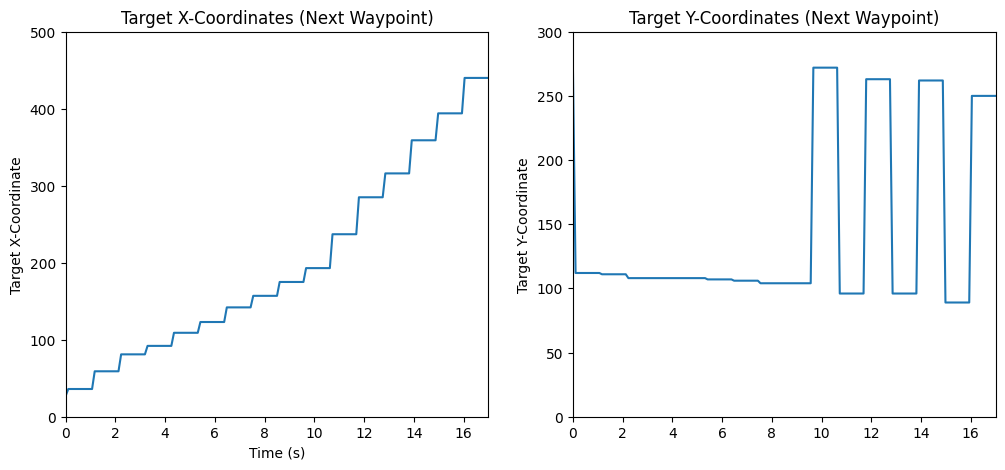

In [20]:
wxs_next = np.array([clicked_points[0][0]] + [x for (x, y) in clicked_points[1:] for _ in range(TS_PER_WAYPOINT)])
wys_next = np.array([clicked_points[0][1]] + [y for (x, y) in clicked_points[1:] for _ in range(TS_PER_WAYPOINT)])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(ts, wxs_next)
plt.title("Target X-Coordinates (Next Waypoint)")
plt.xlabel("Time (s)")
plt.xlim(0, ts[-1])
plt.ylabel("Target X-Coordinate")
plt.ylim(0, 500)

plt.subplot(1, 2, 2)
plt.plot(ts, wys_next)
plt.title("Target Y-Coordinates (Next Waypoint)")
plt.xlim(0, ts[-1])
plt.ylabel("Target Y-Coordinate")
plt.ylim(0, 300)

plt.show()

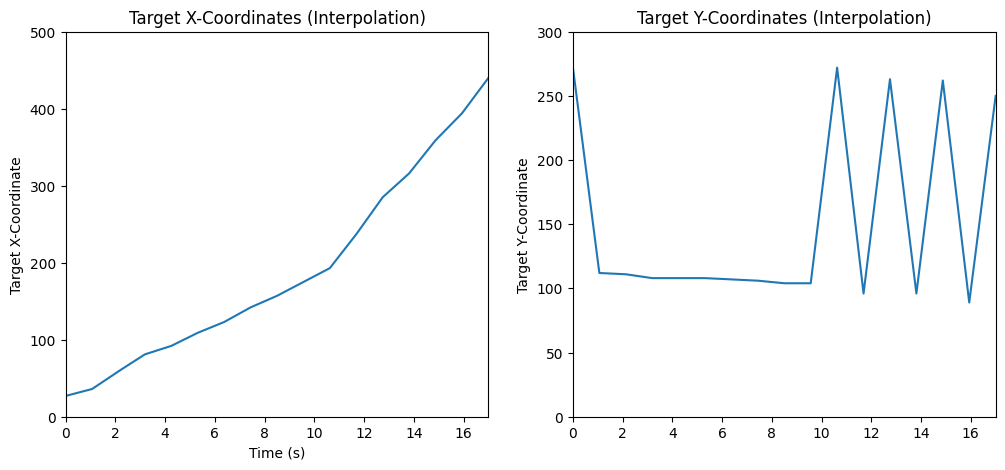

In [21]:
wxs_interpolated = []
wys_interpolated = []

for i in range(len(clicked_points) - 1):
    x1, y1 = clicked_points[i]
    x2, y2 = clicked_points[i + 1]

    wxs_interpolated.extend(np.linspace(x1, x2, TS_PER_WAYPOINT, endpoint=False))
    wys_interpolated.extend(np.linspace(y1, y2, TS_PER_WAYPOINT, endpoint=False))

wxs_interpolated.append(x2)
wys_interpolated.append(y2)

wxs_interpolated = np.array(wxs_interpolated)
wys_interpolated = np.array(wys_interpolated)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(ts, wxs_interpolated)
plt.title("Target X-Coordinates (Interpolation)")
plt.xlabel("Time (s)")
plt.xlim(0, ts[-1])
plt.ylabel("Target X-Coordinate")
plt.ylim(0, 500)

plt.subplot(1, 2, 2)
plt.plot(ts, wys_interpolated)
plt.title("Target Y-Coordinates (Interpolation)")
plt.xlim(0, ts[-1])
plt.ylabel("Target Y-Coordinate")
plt.ylim(0, 300)

plt.show()

Uncentered LQR code:

https://chatgpt.com/g/g-p-69e04533535c8191b283c3a50e93d363-dx-704/c/6ac67f68-4528-83ea-81d2-c9327c4e3d2d

In [22]:
DT = 1 / TS_PER_WAYPOINT

A = np.array([
        [1, 0, DT, 0],
        [0, 1, 0, DT],
        [0, 0, 1,  0],
        [0, 0, 0,  1],
    ])

B = np.array([
    [0.5 * DT**2, 0],
    [0, 0.5 * DT**2],
    [DT, 0],
    [0, DT],
])

In [23]:
Q = np.diag([1.0, 1.0, 0.0, 0.0])
R = np.eye(2)

In [24]:
def finite_horizon_lqr_tracking(A, B, references, Q, R, Q_terminal=None):
    """
    Solve the finite-horizon tracking problem

        sum_t (x_t-r_t)' Q (x_t-r_t) + u_t' R u_t

    subject to

        x_{t+1} = A x_t + B u_t

    Returns K[t], k[t] such that

        u_t = -K[t] @ x_t - k[t]
    """

    T = len(references)

    if Q_terminal is None:
        Q_terminal = Q

    K_list = [None] * T
    k_list = [None] * T

    # Terminal value function:
    #
    # V_T(x) = (x-r_T)' Q_terminal (x-r_T)
    #
    #        = x' P x + 2 p' x + constant

    P = Q_terminal.copy()
    p = -Q_terminal @ references[-1]

    # Work backward in time
    for t in reversed(range(T)):

        H = R + B.T @ P @ B

        # Feedback term
        K = np.linalg.solve(
            H,
            B.T @ P @ A
        )

        # Feedforward / reference-tracking term
        k = np.linalg.solve(
            H,
            B.T @ p
        )

        K_list[t] = K
        k_list[t] = k

        # Current reference
        r = references[t]

        # Update value function for previous timestep
        P_new = (
            Q
            + A.T @ P @ A
            - A.T @ P @ B @ K
        )

        p_new = (
            -Q @ r
            + A.T @ p
            - A.T @ P @ B @ k
        )

        P = P_new
        p = p_new

    return K_list, k_list

In [25]:
def simulate_lqr(x0, A, B, K_list, k_list):
    x = np.asarray(x0, dtype=float)

    states = [x.copy()]
    controls = []

    for K, k in zip(K_list, k_list):
        u = -K @ x - k

        x = A @ x + B @ u

        controls.append(u.copy())
        states.append(x.copy())

    return np.asarray(states), np.asarray(controls)

Use the solver code on our data.

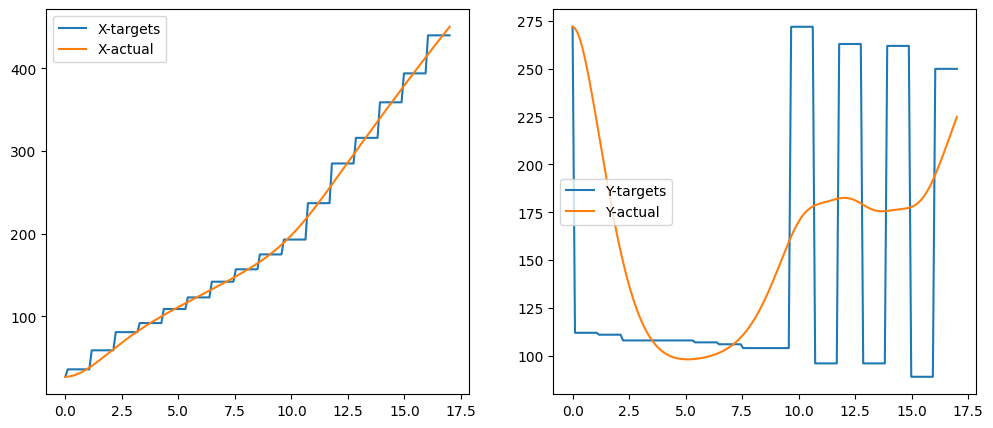

In [26]:
def run_simulation(wxs, wys):
    references = [np.array([wx, wy, 0.0, 0.0]) for wx, wy in zip(wxs, wys)]

    K_list, k_list = finite_horizon_lqr_tracking(A, B, references, Q, R)

    x0 = np.array([
        wxs[0],   # x
        wys[0],   # y
        0.0,   # vx
        0.0,   # vy
    ])

    states, controls = simulate_lqr(
        x0,
        A,
        B,
        K_list,
        k_list
    )

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(ts, wxs, label="X-targets")
    plt.plot(ts, states[:-1, 0], label="X-actual")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(ts, wys, label="Y-targets")
    plt.plot(ts, states[:-1, 1], label="Y-actual")
    plt.legend()
    plt.show()

run_simulation(wxs_next, wys_next)

> make a copy of run_simulation called animate_simulation with the same inputs that animates the movement in x/y space.

In [13]:
import matplotlib.animation as animation
from IPython.display import HTML

def animate_simulation(wxs, wys):
    references = [np.array([wx, wy, 0.0, 0.0]) for wx, wy in zip(wxs, wys)]

    K_list, k_list = finite_horizon_lqr_tracking(A, B, references, Q, R)

    x0 = np.array([
        wxs[0],   # x
        wys[0],   # y
        0.0,      # vx
        0.0,      # vy
    ])

    states, controls = simulate_lqr(
        x0,
        A,
        B,
        K_list,
        k_list
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlim(0, 500)
    ax.set_ylim(0, 300)
    ax.invert_yaxis()  # Invert Y to match HTML canvas convention if needed, or keep standard. Let's invert to align with the HTML clicker.
    ax.set_title("LQR Tracking Simulation in X/Y Space")
    ax.set_xlabel("X Coordinate")
    ax.set_ylabel("Y Coordinate")
    ax.grid(True)

    # Plot target trajectory path
    ax.plot(wxs, wys, 'r--', alpha=0.5, label='Target Path')
    # Plot actual trajectory path as a light line
    actual_line, = ax.plot([], [], 'b-', alpha=0.6, label='Actual Trajectory')
    # Current actual position dot
    point, = ax.plot([], [], 'bo', markersize=8, label='Agent')
    # Current target position dot
    target_point, = ax.plot([], [], 'ro', markersize=6, label='Target')

    ax.legend()

    def init():
        actual_line.set_data([], [])
        point.set_data([], [])
        target_point.set_data([], [])
        return actual_line, point, target_point

    def update(frame):
        # Actual state path up to current frame
        actual_line.set_data(states[:frame+1, 0], states[:frame+1, 1])
        # Current actual state
        point.set_data([states[frame, 0]], [states[frame, 1]])
        # Current reference target
        target_point.set_data([wxs[frame]], [wys[frame]])
        return actual_line, point, target_point

    num_frames = len(wxs)
    ani = animation.FuncAnimation(fig, update, frames=num_frames, init_func=init, blit=True, interval=100)
    plt.close(fig)
    return HTML(ani.to_jshtml())

In [14]:
animate_simulation(wxs_next, wys_next)

Output hidden; open in https://colab.research.google.com to view.

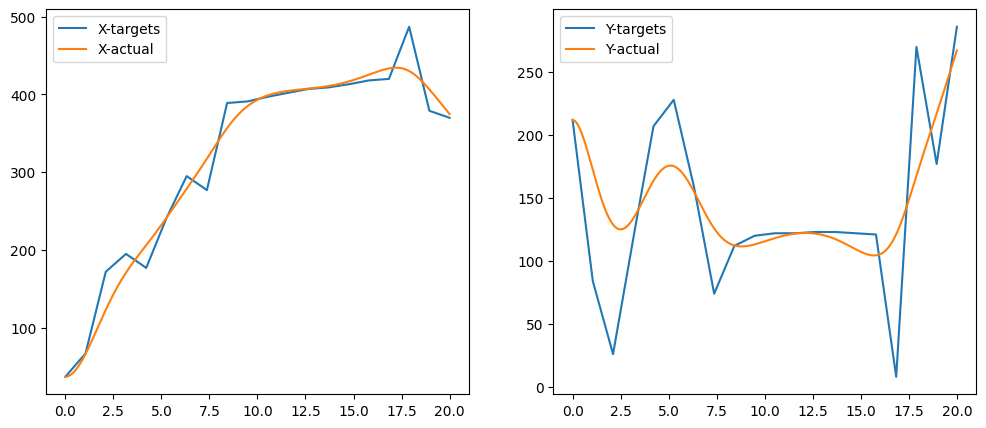

In [15]:
run_simulation(wxs_interpolated, wys_interpolated)

In [16]:
animate_simulation(wxs_interpolated, wys_interpolated)

Output hidden; open in https://colab.research.google.com to view.